Saving customers.csv to customers (3).csv
Dataset loaded successfully!
Columns: ['channel', 'region', 'fresh', 'milk', 'grocery', 'frozen', 'detergentspaper', 'delicatessen']
   channel  region  fresh  milk  grocery  frozen  detergentspaper  \
0        2       3  12669  9656     7561     214             2674   
1        2       3   7057  9810     9568    1762             3293   
2        2       3   6353  8808     7684    2405             3516   
3        1       3  13265  1196     4221    6404              507   
4        2       3  22615  5410     7198    3915             1777   

   delicatessen  
0          1338  
1          1776  
2          7844  
3          1788  
4          5185  

Dataset shape: (440, 8)

Selected spending features:
   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0  12669  9656     7561     214              2674        1338
1   7057  9810     9568    1762              3293        1776
2   6353  8808     7684    2405              3516        7844


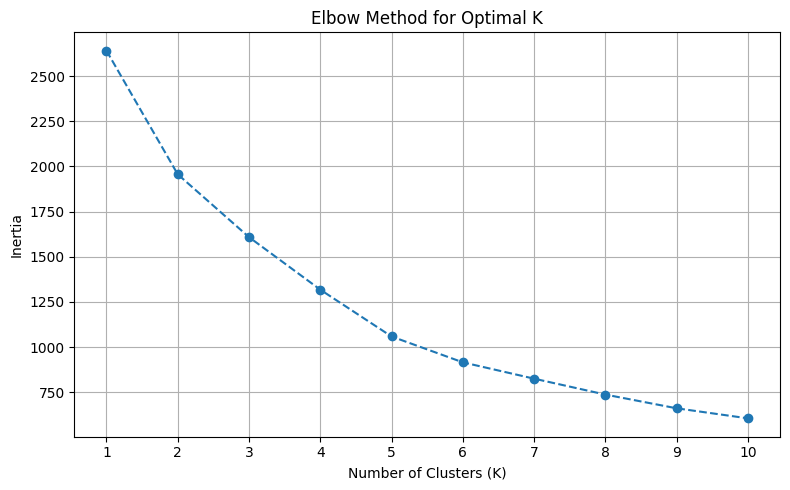


Silhouette Scores:
K = 2: Silhouette Score = 0.5472
K = 3: Silhouette Score = 0.5483
K = 4: Silhouette Score = 0.3485
K = 5: Silhouette Score = 0.3690
K = 6: Silhouette Score = 0.3782
K = 7: Silhouette Score = 0.3343
K = 8: Silhouette Score = 0.3201
K = 9: Silhouette Score = 0.3090
K = 10: Silhouette Score = 0.3112

Chosen number of clusters: 3
   Cluster
0        1
1        1
2        1
3        1
4        1
5        1
6        1
7        1
8        1
9        0

Number of customers in each cluster:
Cluster
0     45
1    393
2      2
Name: count, dtype: int64

Cluster Centroids:
      Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
0  10440.93  19386.42  28656.09   2190.24          13327.80     2374.20
1  12062.91   4115.10   5534.97   2940.68           1696.17     1299.11
2  34782.00  30367.00  16898.00  48701.50            755.50    26776.00


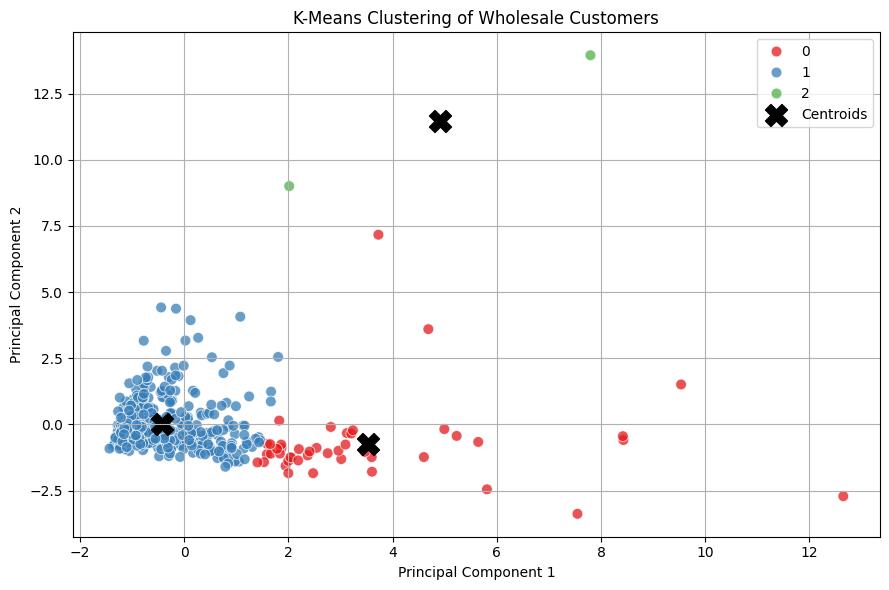


Variance explained by 2 PCA components: 72.46 %
Number of clusters: 3
Number of customers: 440
Features used: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
Final inertia: 1608.43


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# 1. Load Dataset
from google.colab import files
uploaded = files.upload()
df = pd.read_csv("customers.csv")

df.columns = [
    re.sub(r'[^a-z0-9]', '', str(col).lower())
    for col in df.columns
]

print("Dataset loaded successfully!")
print("Columns:", df.columns.tolist())
print(df.head())
print("\nDataset shape:", df.shape)

# 2. Select Features and Preprocess Data
column_map = {
    'fresh': 'Fresh',
    'milk': 'Milk',
    'grocery': 'Grocery',
    'frozen': 'Frozen',
    'detergentspaper': 'Detergents_Paper',
    'delicassen': 'Delicassen',
    'delicatessen': 'Delicassen'
}

selected = {}

for col in df.columns:
    if col in column_map:
        standard_name = column_map[col]
        if standard_name not in selected:
            selected[standard_name] = col

features = [
    'Fresh',
    'Milk',
    'Grocery',
    'Frozen',
    'Detergents_Paper',
    'Delicassen'
]

missing = [f for f in features if f not in selected]

if missing:
    raise ValueError(
        f"Required spending columns not found: {missing}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Select the original columns and rename consistently
X = df[[selected[f] for f in features]].copy()
X.columns = features

# Convert columns to numeric
X = X.apply(pd.to_numeric, errors='coerce')

# Handle missing values
X = X.fillna(X.median())

print("\nSelected spending features:")
print(X.head())

# 3. Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Elbow Method: Find Suitable K

inertia = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

# 5. Silhouette Score
print("\nSilhouette Scores:")

for k in range(2, min(11, len(X_scaled))):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"K = {k}: Silhouette Score = {score:.4f}")

# 6. Apply K-Means Clustering
optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)
df['Cluster'] = cluster_labels

print("\nChosen number of clusters:", optimal_k)
print(df[['Cluster']].head(10))

print("\nNumber of customers in each cluster:")
print(df['Cluster'].value_counts().sort_index())

# 7. Display Cluster Centroids

centroids = scaler.inverse_transform(kmeans.cluster_centers_)

centroid_df = pd.DataFrame(
    centroids,
    columns=features
)

print("\nCluster Centroids:")
print(centroid_df.round(2))

# 8. Visualize Clusters Using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

centroids_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=cluster_labels,
    palette='Set1',
    s=60,
    alpha=0.75
)

plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker='X',
    s=250,
    c='black',
    label='Centroids'
)

plt.title('K-Means Clustering of Wholesale Customers')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(
    "\nVariance explained by 2 PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

print("Number of clusters:", optimal_k)
print("Number of customers:", len(X))
print("Features used:", features)
print("Final inertia:", round(kmeans.inertia_, 2))